# ChiNeutro: ajuste de Qwen3.5 (decoder) con LoRA / QLoRA

Ajusta **Qwen3.5-2B o 4B** para pasar español de Chile a español neutro con el **split oficial del grupo** (`data/entrenamiento/splits/split_oficial.csv`: 3.184 train / 399 val / 397 test) y deja las predicciones en el formato de `evaluacion/` (`id_mistral, frase_chilena, prediccion`). Es la versión decoder del notebook de mT5/mT0, pensada para correr **en local** (RTX 5070 de 12 GB, bf16).

**Cómo usarlo**
1. Deja el notebook dentro del repo `NLP-ChiNeutro` (rama `baseline`, la que tiene el split oficial y `evaluacion/`) y ábrelo en VS Code con el kernel del Python que tiene PyTorch con CUDA.
2. Ejecuta la primera celda (revisa paquetes). Si instalas algo, **reinicia el kernel** antes de seguir.
3. Ajusta la celda de configuración y ejecuta todo. Las salidas quedan en `salidas_qwen/<NOMBRE>/` dentro del repo. Si se corta, vuelve a ejecutar todo y el entrenamiento retoma desde el último checkpoint.

**Qué configuración usar en 12 GB:** `Qwen3.5-2B` con `MODO="lora"`; `Qwen3.5-4B` con `MODO="qlora"` (en bf16 sus pesos solos son unos 8 GB y no queda margen para entrenar). La celda de configuración se detiene si el modo elegido no cabe.

**Qué cambia respecto del notebook de mT5**
- **Decoder, no encoder-decoder:** el prompt y la respuesta van en **una sola secuencia** con la plantilla de chat de Qwen. La pérdida se calcula **solo sobre la respuesta** (y el token de fin de turno `<|im_end|>`); los tokens del prompt valen −100.
- **Qwen3.5 piensa por defecto** (escribe `<think>...` antes de responder y no acepta el interruptor `/nothink`). Aquí se apaga con `enable_thinking=False` tanto al entrenar como al generar, y el notebook comprueba que la plantilla respete ese parámetro.
- **Se carga solo la parte de texto:** `AutoModelForCausalLM` toma el `text_config` del checkpoint multimodal y no carga el codificador de visión (lo revisé en el código de `transformers` 5.18).
- **LoRA también en las capas Gated DeltaNet:** Qwen3.5 alterna 3 capas Gated DeltaNet con 1 de atención, así que además de `q/k/v/o` y el MLP se adaptan `in_proj_qkv`, `in_proj_z` y `out_proj`.
- **Incluye la baseline sin ajuste** (el mismo modelo, mismo prompt) y compara las métricas de val de ambas al final.

**Decisiones que se mantienen:** mismo prompt (`INSTRUCCION_CHAT` de `models/gemma4/comun.py`), LoRA r=16 y alpha=32 como en Gemma, generación greedy y primera línea, **val** para comparar configuraciones y **test** solo para el resultado final.

**Velocidad:** las capas Gated DeltaNet tienen un camino rápido que necesita `triton`, que en Windows normalmente no está (el aviso `triton not found` de PyTorch lo indica). Sin él, `transformers` usa la implementación en PyTorch: funciona, pero es más lenta.

In [2]:
# Celda 1: variables de descarga y revisión de paquetes (va ANTES de importar transformers)
import os
os.environ["HF_XET_HIGH_PERFORMANCE"] = "1"          # descarga en paralelo: el modelo pesa varios GB
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"  # aviso inofensivo de Windows

import importlib.metadata as md

paquetes = ["torch", "transformers", "peft", "accelerate", "bitsandbytes", "sacrebleu", "bert-score", "pandas", "matplotlib"]
faltan = []
for p in paquetes:
    try:
        print(f"{p:14s} {md.version(p)}")
    except md.PackageNotFoundError:
        print(f"{p:14s} NO instalado")
        faltan.append(p)
if faltan:
    print(f"\nInstala con:  %pip install -U {' '.join(faltan)}   y reinicia el kernel antes de seguir")

torch          2.14.0+cu130
transformers   5.18.0
peft           0.22.0
accelerate     1.15.0
bitsandbytes   0.50.2
sacrebleu      2.6.0
bert-score     0.3.13
pandas         3.0.5
matplotlib     3.11.2


In [3]:
%pip install -U peft sacrebleu bert-score

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import torch
assert torch.cuda.is_available(), "torch no ve la GPU: instala el build con CUDA (para la serie 50 hace falta cu128 o superior)"
p = torch.cuda.get_device_properties(0)
BF16 = torch.cuda.get_device_capability(0)[0] >= 8      # RTX 5070 sí
GB = p.total_memory / 1e9
arch = f"{p.major}{p.minor}"                            # 120 en la serie 50 (Blackwell)
print(f"GPU: {p.name} | {GB:.0f} GB | sm_{arch} | bf16 nativo: {BF16} | torch {torch.__version__} (CUDA {torch.version.cuda})")
if not any(arch in a for a in torch.cuda.get_arch_list()):
    print(f"AVISO: este build de torch no lista sm_{arch}; si aparecen errores de kernel, instala torch con CUDA 12.8 o superior")

GPU: NVIDIA GeForce RTX 5070 | 13 GB | sm_120 | bf16 nativo: True | torch 2.14.0+cu130 (CUDA 13.0)


## Configuración

In [5]:
import re

# Modelo de partida (las versiones "-Base" no traen ajuste de instrucciones)
MODELO_ID = "Qwen/Qwen3.5-2B"        # "Qwen/Qwen3.5-2B" | "Qwen/Qwen3.5-4B"
MODO = "lora"                         # "lora" (pesos en bf16) | "qlora" (pesos en 4 bits: para el 4B en 12 GB)

# LoRA: mismos valores que el paso 2 de Gemma (r16, alpha 32)
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
# Atención (q, k, v, o), capas Gated DeltaNet (in_proj_qkv, in_proj_z, out_proj) y MLP (gate, up, down)
LORA_MODULOS = ["q_proj", "k_proj", "v_proj", "o_proj", "in_proj_qkv", "in_proj_z", "out_proj",
                "gate_proj", "up_proj", "down_proj"]

# Entrenamiento
LR = 2e-4                             # LoRA en LLM; mT5 toleraba 5e-4
EPOCAS = 4                            # se queda con la mejor época según la pérdida de validación
LOTE = 8                              # si da falta de memoria: LOTE = 4 y ACUM = 4
ACUM = 2
GRADIENT_CHECKPOINTING = (MODO == "qlora")   # ahorra memoria a cambio de velocidad
SEED = 42

MAX_LEN = 512                         # tope de tokens de prompt + respuesta (hay un assert más abajo)
MAX_NEW_TOKENS = 96

RAMA = "baseline"                     # rama del repo con el split oficial y evaluacion/

# ---- precisión derivada de la GPU y del modo
assert MODO in ("lora", "qlora")
if BF16:
    DTYPE = torch.bfloat16
else:                                 # no debería pasar en una 5070
    DTYPE = torch.float16 if MODO == "qlora" else torch.float32
USAR_BF16, USAR_FP16 = DTYPE == torch.bfloat16, DTYPE == torch.float16

# ---- comprobación de memoria de los pesos (estimación gruesa)
n_b = float(re.search(r"(\d+(?:\.\d+)?)B", MODELO_ID.split("/")[-1]).group(1))   # 2 o 4 (miles de millones)
bytes_param = 0.6 if MODO == "qlora" else (4 if DTYPE == torch.float32 else 2)
est = n_b * bytes_param
print(f"Pesos estimados: {est:.1f} GB de {GB:.0f} GB | dtype: {str(DTYPE).replace('torch.', '')}")
assert est < 0.6 * GB, "No caben los pesos con margen para entrenar: usa MODO='qlora' o el modelo de 2B"

corto = MODELO_ID.split("/")[-1].replace("-", "_")
NOMBRE = f"{corto}_{MODO}_r{LORA_R}"
print("Corrida:", NOMBRE)

Pesos estimados: 4.0 GB de 13 GB | dtype: bfloat16
Corrida: Qwen3.5_2B_lora_r16


## Repo y salidas

In [6]:
import sys, subprocess
from pathlib import Path

# Sube desde la carpeta del notebook hasta encontrar la raíz del repo (la que contiene el split oficial)
marca = "data/entrenamiento/splits/split_oficial.csv"
actual = Path.cwd().resolve()
RAIZ = next((d for d in [actual, *actual.parents] if (d / marca).is_file()), None)
assert RAIZ is not None, f"No encontré {marca} subiendo desde {actual}. Deja el notebook dentro del repo, en la rama {RAMA}"

rama = subprocess.run(["git", "branch", "--show-current"], cwd=RAIZ, capture_output=True, text=True).stdout.strip()
print("Repo:", RAIZ, "| rama:", rama or "(sin git)")
if rama and rama != RAMA:
    print(f"AVISO: el split y evaluacion/ están en la rama '{RAMA}'")

SALIDAS = RAIZ / "salidas_qwen"
DIR_DRIVE = SALIDAS / NOMBRE                      # el nombre se mantiene por compatibilidad con el notebook de mT5
DIR_CKPT, DIR_PRED = DIR_DRIVE / "checkpoints", DIR_DRIVE / "predicciones"
for d in (DIR_CKPT, DIR_PRED):
    d.mkdir(parents=True, exist_ok=True)

gitignore = RAIZ / ".gitignore"
if "salidas_qwen" not in (gitignore.read_text(encoding="utf-8") if gitignore.exists() else ""):
    print("AVISO: agrega 'salidas_qwen/' a .gitignore; los checkpoints pesan cientos de MB y no deben subirse al repo")

sys.path.insert(0, str(RAIZ))
os.chdir(RAIZ)

Repo: C:\Users\conso\OneDrive\Desktop\Universidah\2026-2\NLP\Proyecto\NLP-ChiNeutro | rama: main
AVISO: el split y evaluacion/ están en la rama 'baseline'


## 1. Datos (split oficial)

In [7]:
import pandas as pd
from evaluacion import cargar_split

por_split = {s: cargar_split(s) for s in ("train", "val", "test")}
tamanos = {s: len(d) for s, d in por_split.items()}
print(tamanos)
assert tamanos == {"train": 3184, "val": 399, "test": 397}, "El split no es el oficial"

# Ninguna frase chilena puede repetirse entre splits
frases = {s: set(d.frase_chilena.str.strip().str.lower()) for s, d in por_split.items()}
assert not (frases["train"] & frases["val"]) and not (frases["train"] & frases["test"]) \
    and not (frases["val"] & frases["test"]), "fuga entre splits"

# Mismo prompt que la baseline de mT0 y Gemma (models/gemma4/comun.py)
sys.path.insert(0, str(RAIZ / "models/gemma4"))
from comun import INSTRUCCION_CHAT


def entrada(frase):
    return INSTRUCCION_CHAT.format(chilena=frase.strip())

{'train': 3184, 'val': 399, 'test': 397}


In [8]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained(MODELO_ID)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

FIN_TURNO = "<|im_end|>"                       # token con que el asistente cierra su respuesta
ID_FIN = tok.convert_tokens_to_ids(FIN_TURNO)
assert ID_FIN is not None, f"El tokenizador no tiene {FIN_TURNO}: revisa la plantilla de chat del modelo"


def prompt_de(frase, pensar=False):
    """Prompt completo (turno del usuario + inicio del turno del asistente), con el razonamiento apagado."""
    msgs = [{"role": "user", "content": entrada(frase)}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=pensar)


# Qwen3.5 piensa por defecto: comprobar que la plantilla respeta enable_thinking
ej = por_split["train"].frase_chilena[0]
assert prompt_de(ej, pensar=False) != prompt_de(ej, pensar=True), \
    "La plantilla ignora enable_thinking: el modelo pensaría antes de responder"
print(prompt_de(ej))
print("-----")
print("Final del prompt:", repr(prompt_de(ej)[-60:]))

<|im_start|>user
Traduce la siguiente frase del español de Chile al español neutro. Responde solo con la traducción.

Oye, necesito hablar contigo, recién me cayó la teja con lo de la plata.<|im_end|>
<|im_start|>assistant
<think>

</think>


-----
Final del prompt: 'a plata.<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n'


In [9]:
import torch
from torch.utils.data import Dataset, DataLoader


def a_ejemplos(df):
    """Cada ejemplo = prompt + respuesta + <|im_end|>. Etiquetas: -100 en el prompt, ids reales en la respuesta."""
    ids_l, lab_l, n_prompt, n_resp = [], [], [], []
    for f, n in zip(df.frase_chilena, df.frase_neutralizada):
        p = tok(prompt_de(f), add_special_tokens=False).input_ids
        r = tok(n.strip() + FIN_TURNO, add_special_tokens=False).input_ids
        assert r[-1] == ID_FIN
        ids_l.append(p + r); lab_l.append([-100] * len(p) + r)
        n_prompt.append(len(p)); n_resp.append(len(r))
    return ids_l, lab_l, n_prompt, n_resp


class Ejemplos(Dataset):
    def __init__(self, ids, labels): self.ids, self.labels = ids, labels
    def __len__(self): return len(self.ids)
    def __getitem__(self, i): return {"input_ids": self.ids[i], "labels": self.labels[i]}


def collate(batch):
    """Relleno a la derecha con la pad del tokenizador; las etiquetas de relleno valen -100."""
    L = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), L), tok.pad_token_id, dtype=torch.long)
    lab = torch.full((len(batch), L), -100, dtype=torch.long)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"]); lab[i, :n] = torch.tensor(b["labels"]); att[i, :n] = 1
    return {"input_ids": ids, "attention_mask": att, "labels": lab}


ids_tr, lab_tr, np_tr, nr_tr = a_ejemplos(por_split["train"])
ids_va, lab_va, _, _ = a_ejemplos(por_split["val"])
ds_train, ds_val = Ejemplos(ids_tr, lab_tr), Ejemplos(ids_va, lab_va)

largo_max = max(len(x) for x in ids_tr + ids_va)
print(f"tokens por ejemplo (train): media {sum(map(len, ids_tr)) / len(ids_tr):.0f}, máx {largo_max}")
print(f"prompt: media {sum(np_tr) / len(np_tr):.0f} | respuesta: media {sum(nr_tr) / len(nr_tr):.0f}, máx {max(nr_tr)}")
assert largo_max < MAX_LEN, "algún ejemplo es más largo que MAX_LEN: sube MAX_LEN"

# Revisión visual de la máscara: lo que se aprende es solo lo que está después del prompt
ej0 = ids_tr[0]; lab0 = lab_tr[0]
print("Texto que se aprende:", repr(tok.decode([t for t in lab0 if t != -100])))

tokens por ejemplo (train): media 75, máx 105
prompt: media 55 | respuesta: media 20, máx 37
Texto que se aprende: 'Oye, necesito hablar contigo, acabo de darme cuenta de lo del dinero.<|im_end|>'


## 2. Modelo sin ajustar (baseline)

Se carga solo la parte de texto del checkpoint y se miden dos cosas antes de entrenar: la pérdida en val (`VAL0`, que sirve de referencia y de chequeo de que los pesos cargaron bien) y las predicciones del modelo tal como viene, con el mismo prompt. Con `MODO="qlora"` esta baseline ya corre con los pesos en 4 bits.

In [10]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig, set_seed

set_seed(SEED)
kw = dict(dtype=DTYPE, device_map={"": 0})
if MODO == "qlora":
    kw["quantization_config"] = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=DTYPE)
modelo = AutoModelForCausalLM.from_pretrained(MODELO_ID, **kw)
modelo.eval()
print(type(modelo).__name__, f"| memoria GPU: {torch.cuda.memory_allocated() / 1e9:.1f} GB")


@torch.no_grad()
def loss_val(model, ds, bs=8):
    """Pérdida media por token de respuesta sobre un conjunto."""
    model.eval()
    tot, n = 0.0, 0
    for b in DataLoader(ds, batch_size=bs, shuffle=False, collate_fn=collate):
        b = {k: v.to(model.device) for k, v in b.items()}
        c = (b["labels"][:, 1:] != -100).sum().item()
        tot += model(**b).loss.item() * c
        n += c
    return tot / n


VAL0 = loss_val(modelo, ds_val)
print(f"Sin ajustar | val loss {VAL0:.3f}")
assert VAL0 < 8, "La pérdida inicial es demasiado alta: los pesos no cargaron bien (con pesos al azar sería ~12)"

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Qwen3_5ForCausalLM | memoria GPU: 3.8 GB


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


Sin ajustar | val loss 1.236


In [11]:
import json

tok.padding_side = "left"      # para generar en lotes el relleno va a la izquierda


@torch.no_grad()
def traducir(frases, bs=16):
    modelo.eval()
    salidas = []
    for i in range(0, len(frases), bs):
        x = tok([prompt_de(f) for f in frases[i:i + bs]], return_tensors="pt", padding=True,
                add_special_tokens=False).to(modelo.device)
        out = modelo.generate(**x, do_sample=False, num_beams=1, temperature=None, top_p=None, top_k=None,
                              max_new_tokens=MAX_NEW_TOKENS, use_cache=True,
                              eos_token_id=list({ID_FIN, tok.eos_token_id} - {None}), pad_token_id=tok.pad_token_id)
        for s in tok.batch_decode(out[:, x["input_ids"].shape[1]:], skip_special_tokens=True):
            s = re.sub(r"<think>.*?</think>", "", s, flags=re.S)       # por si el modelo llegara a pensar
            salidas.append(s.strip().split("\n")[0].strip())          # igual que la baseline: primera línea
    return salidas


def predecir(etiqueta=""):
    """Predice val y test y guarda los CSV en el formato de evaluacion/."""
    rutas = {}
    for s in ("val", "test"):
        df = por_split[s][["id_mistral", "frase_chilena"]].copy()
        df["prediccion"] = traducir(df.frase_chilena.tolist())
        nom = f"predicciones_{NOMBRE}" + (f"_{etiqueta}" if etiqueta else "") + f"_{s}.csv"
        rutas[s] = DIR_PRED / nom
        df.to_csv(rutas[s], index=False)
        print(f"{s}: {nom} | vacías: {(df.prediccion == '').sum()} "
              f"| copia literal: {(df.prediccion.str.strip() == df.frase_chilena.str.strip()).mean():.1%}")
    return rutas


# Chequeo: con capas de atención lineal y relleno a la izquierda, el lote no debería cambiar la salida
muestra = por_split["val"].frase_chilena[:8].tolist()
en_lote = traducir(muestra, bs=8)
una_a_una = [traducir([f], bs=1)[0] for f in muestra]
print(f"Distintas entre lote y una a una: {sum(a != b for a, b in zip(en_lote, una_a_una))}/8 "
      "(unas pocas por diferencias numéricas son normales; si son casi todas, baja `bs` en traducir)")

RUTAS_BASE = predecir("sin_ajuste")

[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


Distintas entre lote y una a una: 0/8 (unas pocas por diferencias numéricas son normales; si son casi todas, baja `bs` en traducir)
val: predicciones_Qwen3.5_2B_lora_r16_sin_ajuste_val.csv | vacías: 0 | copia literal: 22.8%
test: predicciones_Qwen3.5_2B_lora_r16_sin_ajuste_test.csv | vacías: 0 | copia literal: 25.7%


## 3. LoRA

In [12]:
from collections import Counter
from peft import LoraConfig, get_peft_model

modelo = get_peft_model(modelo, LoraConfig(task_type="CAUSAL_LM", r=LORA_R, lora_alpha=LORA_ALPHA,
                                           lora_dropout=LORA_DROPOUT, target_modules=LORA_MODULOS))
modelo.print_trainable_parameters()
modelo.config.use_cache = False


# Qué capas recibieron adaptador (deben aparecer las de atención, las Gated DeltaNet y el MLP)
cuenta = Counter(n.split(".")[-2] for n, _ in modelo.named_modules() if n.endswith(".lora_A"))
print(dict(cuenta))
assert {"in_proj_qkv", "out_proj", "q_proj", "gate_proj"} <= set(cuenta), "Faltan capas en LORA_MODULOS"

W1120 19:23:01.149000 34768 site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


trainable params: 15,630,336 || all params: 1,897,455,424 || trainable%: 0.8238
{'out_proj': 18, 'in_proj_qkv': 18, 'in_proj_z': 18, 'gate_proj': 24, 'up_proj': 24, 'down_proj': 24, 'q_proj': 6, 'k_proj': 6, 'v_proj': 6, 'o_proj': 6}


## 4. Entrenamiento

Evalúa la pérdida en val al final de cada época y se queda con la mejor. Los checkpoints (solo el adaptador, pocos MB) van a Drive o a `salidas_qwen/`: si se corta, vuelve a ejecutar todo y retoma.

In [13]:
import math
from transformers import Trainer, TrainingArguments

pasos_totales = math.ceil(len(ds_train) / (LOTE * ACUM)) * EPOCAS
args = TrainingArguments(
    output_dir=str(DIR_CKPT),
    per_device_train_batch_size=LOTE,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=ACUM,
    num_train_epochs=EPOCAS,
    learning_rate=LR,
    lr_scheduler_type="cosine",
    warmup_steps=int(0.05 * pasos_totales),
    optim="adamw_torch",
    bf16=USAR_BF16,
    fp16=USAR_FP16,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=20,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    label_names=["labels"],
    remove_unused_columns=False,
    report_to="none",
    seed=SEED,
)
trainer = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val, data_collator=collate)

hay_ckpt = any(DIR_CKPT.glob("checkpoint-*"))
print("Retomando desde checkpoint" if hay_ckpt else "Entrenamiento desde cero", f"| pasos totales: {pasos_totales}")
trainer.train(resume_from_checkpoint=hay_ckpt)
trainer.save_model(str(DIR_DRIVE / "adaptador_final"))
tok.save_pretrained(str(DIR_DRIVE / "adaptador_final"))

Entrenamiento desde cero | pasos totales: 796


Epoch,Training Loss,Validation Loss
1,0.618885,0.559404
2,0.326540,0.483145
3,0.107753,0.515384
4,0.028347,0.581054


('C:\\Users\\conso\\OneDrive\\Desktop\\Universidah\\2026-2\\NLP\\Proyecto\\NLP-ChiNeutro\\salidas_qwen\\Qwen3.5_2B_lora_r16\\adaptador_final\\tokenizer_config.json',
 'C:\\Users\\conso\\OneDrive\\Desktop\\Universidah\\2026-2\\NLP\\Proyecto\\NLP-ChiNeutro\\salidas_qwen\\Qwen3.5_2B_lora_r16\\adaptador_final\\chat_template.jinja',
 'C:\\Users\\conso\\OneDrive\\Desktop\\Universidah\\2026-2\\NLP\\Proyecto\\NLP-ChiNeutro\\salidas_qwen\\Qwen3.5_2B_lora_r16\\adaptador_final\\tokenizer.json')

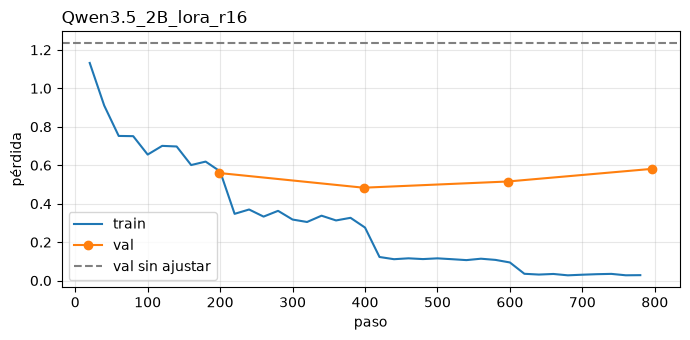

Mejor checkpoint: C:\Users\conso\OneDrive\Desktop\Universidah\2026-2\NLP\Proyecto\NLP-ChiNeutro\salidas_qwen\Qwen3.5_2B_lora_r16\checkpoints\checkpoint-398 | eval_loss: 0.4831453561782837


In [14]:
import matplotlib.pyplot as plt

hist = trainer.state.log_history
tr = [(h["step"], h["loss"]) for h in hist if "loss" in h]
ev = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]
assert not any(math.isnan(l) for _, l in tr + ev), \
    "La pérdida dio NaN: revisa la precisión (DTYPE); en una 5070 debería ser bf16"

plt.figure(figsize=(7, 3.5))
plt.plot(*zip(*tr), label="train")
plt.plot(*zip(*ev), "o-", label="val")
plt.axhline(VAL0, ls="--", color="gray", label="val sin ajustar")
plt.xlabel("paso"); plt.ylabel("pérdida"); plt.title(NOMBRE, loc="left"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(DIR_DRIVE / "curva_perdida.png", dpi=150); plt.show()
print("Mejor checkpoint:", trainer.state.best_model_checkpoint, "| eval_loss:", trainer.state.best_metric)
json.dump(hist, open(DIR_DRIVE / "historial.json", "w"), indent=1)

## 5. Predicciones del modelo ajustado (val y test)

In [15]:
modelo = trainer.model           # con el mejor checkpoint cargado
if GRADIENT_CHECKPOINTING:
    modelo.gradient_checkpointing_disable()
RUTAS_FT = predecir()

val: predicciones_Qwen3.5_2B_lora_r16_val.csv | vacías: 0 | copia literal: 0.5%
test: predicciones_Qwen3.5_2B_lora_r16_test.csv | vacías: 0 | copia literal: 1.0%


In [16]:
# Ejemplos de val para revisar a ojo: baseline vs ajustado
ej = por_split["val"][["termino", "frase_chilena", "frase_neutralizada"]].copy()
ej["sin_ajuste"] = pd.read_csv(RUTAS_BASE["val"]).prediccion
ej["ajustado"] = pd.read_csv(RUTAS_FT["val"]).prediccion
pd.set_option("display.max_colwidth", 100)
display(ej.sample(12, random_state=SEED))

,termino,frase_chilena,frase_neutralizada,sin_ajuste,ajustado
198,parlanchin,"Yo soy parlanchín, en las entrevistas de trabajo me tengo que controlar harto.","Yo soy hablador, en las entrevistas de trabajo me tengo que controlar mucho.","Soy parlanchín, en las entrevistas de trabajo tengo que controlarme bastante.","Yo soy hablador, en las entrevistas de trabajo me tengo que controlar mucho."
349,Gorrear,Al Pato lo gorrearon tres veces y todavía sigue con la mina.,A Pato le pusieron los cuernos tres veces y todavía sigue con esa chica.,Al pato le dieron tres gorras y aún sigue con la mina.,A Pato lo coquetearon tres veces y todavía sigue con la chica.
33,con pica,"El abogado metió la demanda con pica, quería que la empresa pagara por lo que le hicieron.",El abogado presentó la demanda con afán de venganza; quería que la empresa pagara por lo que le ...,"El abogado presentó la demanda con pica, deseaba que la empresa pagara por lo que le habían hecho.","El abogado presentó la demanda con mucha energía, quería que la empresa pagara por lo que le hic..."
208,pegote,"La polola del Mati es súper pegote, ni a la pichanga lo deja ir solo.","La novia de Mati lo sigue a todas partes, ni al partido de fútbol con sus amigos lo deja ir solo.","La polola del Mati es súper pegote, ni a la pichanga lo deja ir solo.","La novia de Mati es muy guapísima, ni a la fiesta patria lo deja ir solo."
93,sarpao,"Ese loco anda sarpao, mejor no lo miremos ni le hablemos.","Ese tipo anda agresivo, mejor no lo miremos ni le hablemos.","Ese loco anda sarpao, mejor no lo miremos ni le hablemos.","Ese tipo anda con el pelo teñido de rubio, mejor no lo miremos ni le hablemos."
84,Sacar la cresta,"Bájate de ese techo altiro, te vai a sacar la cresta si te resbalai.","Bájate de ese techo ahora mismo, te vas a dar un golpe tremendo si te resbalas.","Bájate de ese techo alto, te vas a sacar la cresta si te resbalas.","Bájate de ese techo de inmediato, te vas a dar una paliza si te resbalas."
374,junta,"Esta semana no voy a la junta, tengo que entregar una pega el lunes.","Esta semana no voy a la reunión, tengo que entregar un trabajo el lunes.","Esta semana no asistiré a la junta, tengo que entregar una pega el lunes.","Esta semana no voy a la reunión, tengo que entregar un trabajo el lunes."
94,se bugeo,Se me bugeó el cerebro en la prueba y no me acordé de ninguna fórmula.,Se me bloqueó la mente en el examen y no me acordé de ninguna fórmula.,"En la prueba, mi cerebro se me fue y no me acordé de ninguna fórmula.",Se me descompuso la memoria en el examen y no me acordé de ninguna fórmula.
222,Piola,"Quédate piola con lo del carrete, que mi mamá no se puede enterar.","No digas nada de lo de la fiesta, que mi mamá no se puede enterar.","Que te quedes piola con lo del carrete, que mi mamá no se puede enterar.","Quétate con lo de la fiesta, que mi mamá no se puede enterar."
126,ta mal pelao el chancho,"Los de arriba ganan millones y los profes una miseria, ta mal pelao el chancho en este país.","Los de arriba ganan millones y los profesores una miseria, la riqueza está mal repartida en este...","Los de arriba ganan millones y los profesores una miseria, tal mal pelao el chancho en este país.","Los de arriba ganan millones y los profesores una miseria, eso es injusto en este país."


## 6. Métricas automáticas en val (sin juez)

BLEU, % de términos chilenos retenidos y BERTScore con el pipeline del grupo, para la baseline y para el modelo ajustado. Úsalas para comparar configuraciones. El juez (Opus vía Claude Code) se corre después en tu computador, sobre test, con la configuración ya elegida.

In [17]:
import gc
del trainer, modelo
gc.collect(); torch.cuda.empty_cache()

from evaluacion import evaluar

resumenes = {}
for nombre, ruta in (("sin ajuste", RUTAS_BASE["val"]), (f"ajustado ({NOMBRE})", RUTAS_FT["val"])):
    resumenes[nombre], _ = evaluar(str(ruta), juez=False)

tabla = pd.json_normalize(list(resumenes.values()))
tabla.index = list(resumenes)
display(tabla.round(3).T)
json.dump(resumenes, open(DIR_DRIVE / "metricas_val.json", "w"), ensure_ascii=False, indent=1, default=float)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-large
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
c:\Users\conso\AppData\Local\Programs\Python\Python311\Lib\site-packages\bert_score\scorer.py:139: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\py

-> C:\Users\conso\OneDrive\Desktop\Universidah\2026-2\NLP\Proyecto\NLP-ChiNeutro\salidas_qwen\Qwen3.5_2B_lora_r16\predicciones\predicciones_Qwen3.5_2B_lora_r16_sin_ajuste_val_evaluacion.json
-> C:\Users\conso\OneDrive\Desktop\Universidah\2026-2\NLP\Proyecto\NLP-ChiNeutro\salidas_qwen\Qwen3.5_2B_lora_r16\predicciones\predicciones_Qwen3.5_2B_lora_r16_sin_ajuste_val_por_frase.csv


Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-large
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


-> C:\Users\conso\OneDrive\Desktop\Universidah\2026-2\NLP\Proyecto\NLP-ChiNeutro\salidas_qwen\Qwen3.5_2B_lora_r16\predicciones\predicciones_Qwen3.5_2B_lora_r16_val_evaluacion.json
-> C:\Users\conso\OneDrive\Desktop\Universidah\2026-2\NLP\Proyecto\NLP-ChiNeutro\salidas_qwen\Qwen3.5_2B_lora_r16\predicciones\predicciones_Qwen3.5_2B_lora_r16_val_por_frase.csv


,sin ajuste,ajustado (Qwen3.5_2B_lora_r16)
n,399,399
bleu,46.77,67.38
terminos_retenidos_%,62.7,3.1
bertscore_f1,0.659,0.822
bertscore_contra,referencia,referencia
